# RAG over the DPDP Act, 2023: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document:** *The Digital Personal Data Protection Act, 2023* (India, Act No. 22 of 2023), the official Gazette PDF (21 pages).
It is a dense legal text: general duties are qualified by exceptions in *other* sections (Section 17 exemptions),
penalties live in a separate Schedule, and many provisions are phrased as negations ("shall not", "nothing contained in").

**Two pipelines over the same frozen chunk corpus**

| Step | Pipeline 1: Baseline | Pipeline 2: Re-ranking |
|---|---|---|
| Retrieve | Bi-encoder `all-MiniLM-L6-v2` + FAISS inner product over L2-normalised vectors (= cosine), **top 10** | the **same** top 10 |
| Re-rank | none | Cross-encoder `cross-encoder/ms-marco-MiniLM-L-6-v2` scores all 10 (query, chunk) pairs |
| Generate | top 3 → LLM → **Answer 1** | top 3 after re-ranking → LLM (identical prompt) → **Answer 2** |

**LLM:** `Qwen/Qwen2.5-3B-Instruct`, run locally (open weights, Hugging Face `transformers`, greedy decoding). No API key is needed.

**Notebook map**
1. Setup  2. Load the PDF  3. Parse & chunk  4. Pipeline 1  5. Pipeline 2  6. LLM + prompt
7. Query set with gold labels  8. Retrieval evaluation on all queries  9. Failure-mode deep dives (rank shifts + Answer 1 vs Answer 2)
10. Latency profiling  11. Scaling: why not cross-encode the whole corpus?  12. Saved artifacts

## 1. Setup

In [1]:
# Core libraries
import os, re, json, time, hashlib, platform, statistics, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import faiss
import pymupdf as fitz  # PyMuPDF
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# ---- configuration (every number used later lives here) ----
ROOT        = Path.cwd()
DATA_DIR    = ROOT / "data"
OUT_DIR     = ROOT / "artifacts"
FIG_DIR     = OUT_DIR / "figures"
for d in (DATA_DIR, OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

PDF_PATH    = DATA_DIR / "dpdp_act_2023.pdf"
PDF_URL     = "https://www.meity.gov.in/static/uploads/2024/06/2bf1f0e9f04e6fb4f8fef35e82c42aa5.pdf"

BI_ENCODER    = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER = "cross-encoder/ms-marco-MiniLM-L-6-v2"
LLM_NAME      = "Qwen/Qwen2.5-3B-Instruct"

TOP_K       = 10    # candidates from the bi-encoder
TOP_N       = 3     # chunks given to the LLM
MAX_WORDS   = 170   # chunk size limit in words (~ MiniLM's 256-token window)
SEED        = 0

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED); np.random.seed(SEED)

# chart colours (validated categorical slots 1-3 + neutral grey)
C_BASE, C_RERANK, C_GOLD, C_GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b5b3ad"

print("python", platform.python_version(), "| torch", torch.__version__, "| device", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor())

D:\antigravityt\LMA\ASSIGNMENT rag\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.12.10 | torch 2.6.0+cu124 | device cuda | NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Load the PDF
The Act is downloaded from the Ministry of Electronics & IT (MeitY) website if it is not already in `data/`.
A SHA-256 hash is printed so the exact file can be verified.

In [2]:
if not PDF_PATH.exists():
    req = urllib.request.Request(PDF_URL, headers={"User-Agent": "Mozilla/5.0"})
    PDF_PATH.write_bytes(urllib.request.urlopen(req, timeout=60).read())

pdf_bytes = PDF_PATH.read_bytes()
print("file   :", PDF_PATH.name, f"({len(pdf_bytes)/1024:.0f} KB)")
print("sha256 :", hashlib.sha256(pdf_bytes).hexdigest())
print("pages  :", fitz.open(PDF_PATH).page_count)

file   : dpdp_act_2023.pdf (178 KB)
sha256 : 4deb23981d3010c8225a2ff6149e7243dc2268455b299e283afebdd7b72a7d15
pages  : 21


## 3. Parsing & structure-aware chunking

Plain text extraction of a Gazette PDF is messy, so the PDF is read **block by block with coordinates** (PyMuPDF):

* **Running headers** (`THE GAZETTE OF INDIA EXTRAORDINARY ...`, y < 88 pt) are dropped, as is the bilingual cover-page masthead.
* **Margin notes** (the section titles printed in the left/right margin, e.g. *"Exemptions."*) are separated from the body by x-position
  and attached to the section they sit next to. Margin citations of other Acts ("24 of 1997.") are discarded.
* **The penalty Schedule** is a 3-column table. Text extraction returns the columns separately, which would separate each breach from its
  penalty amount, so the rows are rebuilt by matching y-coordinates.

**Chunking rule.** Never cross a section boundary; inside a section, split at numbered sub-sections `(1), (2)…` and pack them greedily up to
`MAX_WORDS`. Illustrations stay with the sub-section they illustrate. An oversized sub-section is split at clause markers `(a), (b)…`.
Each chunk starts with a header line *"Chapter … – Section N: title"* so that a fragment like *"(b) cause its Data Processor to erase…"*
still carries its context. Both pipelines use exactly this corpus.

In [3]:
BODY_X0, BODY_X1, HEADER_Y = 110, 482, 88          # body column and header band (PDF points)
ACT_CITATION = re.compile(r"^\d+ of \d{4}\.?$")     # e.g. "24 of 1997." in the margin

def clean(s: str) -> str:
    """Normalise whitespace and spacing quirks such as '( a)' -> '(a)'."""
    s = s.replace(" ", " ")
    s = re.sub(r"\(\s*(\w+)\s*\)", r"(\1)", s)
    return re.sub(r"\s+", " ", s).strip()

def read_pages(path):
    """Return, per page, the body blocks (y, x, text) and the margin notes (y, text)."""
    pages = []
    for pno, page in enumerate(fitz.open(path), start=1):
        body, margin = [], []
        for x0, y0, x1, y1, raw, *_ in page.get_text("blocks"):
            raw = "\n".join(l for l in raw.split("\n") if not ACT_CITATION.match(l.strip()))
            txt = clean(raw)
            if not txt or y0 < HEADER_Y:
                continue
            # margin notes sit left (even pages) or right (odd pages) of the body;
            # PyMuPDF sometimes merges both margins into one very wide block
            if x1 < BODY_X0 + 5 or x0 > BODY_X1 or (x0 < 100 and x1 > 500):
                margin.append((y0, txt))
            else:
                body.append((y0, x0, txt))
        pages.append(dict(page=pno, body=sorted(body), margin=sorted(margin)))
    return pages

def parse_schedule(page):
    """Rebuild the Schedule table: pair each 'Breach ...' cell with the penalty cell on the same row."""
    desc = [(y, t) for y, x, t in page["body"] if 150 < x < 200 and t.startswith(("Breach in", "Breach of any"))]
    pen  = [(y, t) for y, x, t in page["body"] if 400 < x < 420]
    rows = []
    for i, (y, d) in enumerate(sorted(desc), start=1):
        p = min(pen, key=lambda q: abs(q[0] - y))[1]
        rows.append(f"{i}. {d} Penalty: {p}")
    return rows

def split_sections(pages):
    """Walk the body blocks in reading order and group them into numbered sections."""
    started, chapter, chapter_title, want_title = False, "Preamble", "", False
    sections, cur, used, schedule_rows = [], None, set(), []
    for pg in pages:
        if any("THE SCHEDULE" in t for _, _, t in pg["body"]):
            schedule_rows = parse_schedule(pg)
            continue
        for y, x, t in pg["body"]:
            if not started:                                     # skip the Gazette cover masthead
                started = t.startswith("THE DIGITAL PERSONAL DATA PROTECTION ACT")
                if not started:
                    continue
            if t.startswith(("UPLOADED BY", "DR. REETA")):
                continue
            m = re.match(r"^CHAPTER ([IVX]+)$", t)
            if m:
                chapter, want_title = f"Chapter {m.group(1)}", True
                continue
            if want_title:
                chapter_title, want_title = t.title(), False
                continue
            m = re.match(r"^(\d+)\.\s", t)
            next_no = cur["no"] + 1 if cur else 1
            if m and int(m.group(1)) == next_no:              # only accept the next section number
                free = [n for n in pg["margin"] if n not in used]
                note = min(free, key=lambda n: abs(n[0] - y)) if free else None
                title = ""
                if note and abs(note[0] - y) < 80:
                    used.add(note)
                    title = note[1].rstrip(".")
                cur = dict(no=next_no, title=title, chapter=chapter, chapter_title=chapter_title,
                           blocks=[], pages=set())
                sections.append(cur)
            if cur is None:                                     # long title + enacting formula
                cur = dict(no=0, title="Long title", chapter="Preamble", chapter_title="",
                           blocks=[], pages=set())
                sections.append(cur)
            cur["blocks"].append(t)
            cur["pages"].add(pg["page"])
    return sections, schedule_rows

def pack(units, max_words):
    """Greedy packing of text units into groups of at most max_words words."""
    out, buf = [], []
    for u in units:
        if buf and len(" ".join(buf + [u]).split()) > max_words:
            out.append(buf); buf = []
        buf.append(u)
    if buf: out.append(buf)
    return out

def build_chunks(path, max_words=MAX_WORDS):
    sections, schedule_rows = split_sections(read_pages(path))
    chunks = []
    for sec in sections:
        # 1) units = numbered sub-sections "(1)", "(2)" ... (illustrations stay with their sub-section)
        units = []
        for i, b in enumerate(sec["blocks"]):
            if i == 0 or re.match(r"^\(\d+\)", b):
                units.append(b)
            else:
                units[-1] += " " + b
        # 2) a unit that is still too long is split at clause markers "(a)", "(b)" ...
        pieces = []
        for u in units:
            if len(u.split()) <= max_words:
                pieces.append(u); continue
            acc = ""
            for seg in re.split(r"(?=\s\([a-z]{1,2}\)\s)", u):
                if acc and len((acc + seg).split()) > max_words:
                    pieces.append(acc.strip()); acc = seg
                else:
                    acc += seg
            pieces.append(acc.strip())
        # 3) pack, and prefix each chunk with its chapter/section header
        head = (f"{sec['chapter']} ({sec['chapter_title']}) - Section {sec['no']}: {sec['title']}"
                if sec["no"] else "Preamble - Long title")
        for part, grp in enumerate(pack(pieces, max_words), start=1):
            chunks.append(dict(chunk_id=len(chunks), section=str(sec["no"]), part=part,
                               pages=sorted(sec["pages"]), header=head,
                               text=head + "\n" + " ".join(grp)))
    head = "The Schedule - monetary penalties [See section 33(1)]"
    half = (len(schedule_rows) + 1) // 2
    for part, rows in enumerate([schedule_rows[:half], schedule_rows[half:]], start=1):
        chunks.append(dict(chunk_id=len(chunks), section="Schedule", part=part, pages=[21],
                           header=head, text=head + "\n" + " ".join(rows)))
    return chunks

chunks = build_chunks(PDF_PATH)
chunk_texts = [c["text"] for c in chunks]

with open(OUT_DIR / "chunks.jsonl", "w", encoding="utf-8") as f:
    for c in chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")

words = [len(t.split()) for t in chunk_texts]
print(f"{len(chunks)} chunks | words per chunk: min {min(words)}, median {int(np.median(words))}, max {max(words)}")
print(f"distinct units: {len({c['section'] for c in chunks})} (44 sections + long title + Schedule)")

92 chunks | words per chunk: min 30, median 133, max 186
distinct units: 46 (44 sections + long title + Schedule)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 25758.01it/s]


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (263 > 256). Running this sequence through the model will result in indexing errors


bi-encoder tokens per chunk: max 269 (limit 256), mean 158
chunks over the limit (lose their last few tokens in the bi-encoder only): [(83, 263), (89, 269)]


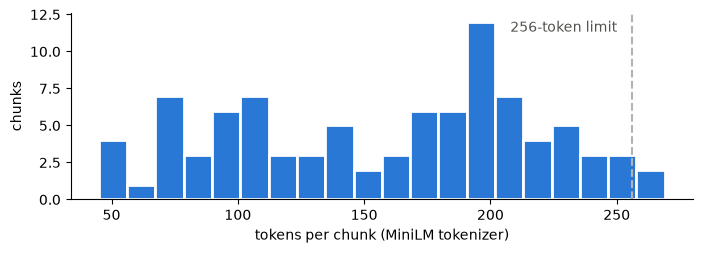

--- chunk 9 ---
Chapter II (Obligations Of Data Fiduciary) - Section 4: Grounds for processing personal data
4. (1) A person may process the personal data of a Data Principal only in accordance with the provisions of this Act and for a lawful purpose,— (a) for which the Data Principal has given her consent; or (b) for certain legitimate uses. (2) For the purposes of this section, the expression “lawful purpose” means any purpose which is not expressly forbidden by law.

--- chunk 46 ---
Chapter IV (Special Provisions) - Section 17: Exemptions
(3) The Central Government may, having regard to the volume and nature of personal data processed, notify certain Data Fiduciaries or class of Data Fiduciaries, including startups, as Data Fiduciaries to whom the provisions of section 5, sub-sections (3) and (7) of section 8 and sections 10 and 11 shall not apply. Explanation.—For the purposes of this sub-section, the term “startup” means a private limited company or a partnership firm or a limite

In [4]:
# Sanity check 1: no chunk is longer than the bi-encoder's 256 word-piece window (otherwise it is silently truncated)
tok = SentenceTransformer(BI_ENCODER, device="cpu").tokenizer
n_tokens = [len(tok(t)["input_ids"]) for t in chunk_texts]
over = [(i, n) for i, n in enumerate(n_tokens) if n > 256]
print(f"bi-encoder tokens per chunk: max {max(n_tokens)} (limit 256), mean {np.mean(n_tokens):.0f}")
print(f"chunks over the limit (lose their last few tokens in the bi-encoder only): {over}")

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(n_tokens, bins=20, color=C_BASE, edgecolor="white", linewidth=2)
ax.axvline(256, color=C_GREY, ls="--", lw=1.5); ax.text(250, ax.get_ylim()[1]*0.9, "256-token limit", ha="right", color="#52514e")
ax.set_xlabel("tokens per chunk (MiniLM tokenizer)"); ax.set_ylabel("chunks")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()
plt.savefig(FIG_DIR / "chunk_token_hist.png", dpi=150); plt.show()

# Sanity check 2: look at a few chunks, including the rebuilt Schedule rows
for i in [9, 46, len(chunks) - 2]:
    print(f"--- chunk {i} ---\n{chunks[i]['text']}\n")

In [5]:
# The whole corpus at a glance: one row per chunk
corpus_df = pd.DataFrame([{"chunk": c["chunk_id"], "section": c["section"], "part": c["part"],
                           "pages": c["pages"], "words": len(c["text"].split()),
                           "header": c["header"]} for c in chunks])
corpus_df.head(12)

,chunk,section,part,pages,words,header
0,0,0,1,[1],79,Preamble - Long title
1,1,1,1,[1],84,Chapter I (Preliminary) - Section 1: Short title and commencement
2,2,2,1,"[2, 3]",152,Chapter I (Preliminary) - Section 2: Definitions
3,3,2,2,"[2, 3]",140,Chapter I (Preliminary) - Section 2: Definitions
4,4,2,3,"[2, 3]",176,Chapter I (Preliminary) - Section 2: Definitions
5,5,2,4,"[2, 3]",132,Chapter I (Preliminary) - Section 2: Definitions
6,6,2,5,"[2, 3]",146,Chapter I (Preliminary) - Section 2: Definitions
7,7,3,1,"[3, 4]",107,Chapter I (Preliminary) - Section 3: Application of Act
8,8,3,2,"[3, 4]",90,Chapter I (Preliminary) - Section 3: Application of Act
9,9,4,1,[4],78,Chapter II (Obligations Of Data Fiduciary) - Section 4: Grounds for processing personal data


## 4. Pipeline 1 – Baseline (bi-encoder + vector store)

The bi-encoder embeds each chunk **once, independently of any query**. Vectors are L2-normalised, so the inner product in
`faiss.IndexFlatIP` equals cosine similarity. At query time only the query is embedded, and the index returns the 10 nearest chunks.
`IndexFlatIP` is exact (brute force), which is fine for 92 chunks; a large corpus would use an approximate index such as HNSW or IVF.

In [6]:
bi_encoder = SentenceTransformer(BI_ENCODER, device=DEVICE)

t0 = time.perf_counter()
chunk_emb = bi_encoder.encode(chunk_texts, batch_size=32, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False).astype("float32")
index_time = time.perf_counter() - t0

index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
np.save(OUT_DIR / "chunk_embeddings.npy", chunk_emb)
print(f"indexed {index.ntotal} chunks, dim {chunk_emb.shape[1]}, offline indexing took {index_time*1000:.0f} ms")

def baseline_retrieve(query: str, k: int = TOP_K):
    """Pipeline 1, steps a-b: embed the query and return the top-k chunks by cosine similarity."""
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    scores, ids = index.search(q, k)
    return [{"chunk_id": int(i), "bi_rank": r + 1, "bi_score": float(s)}
            for r, (i, s) in enumerate(zip(ids[0], scores[0]))]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5344.19it/s]

indexed 92 chunks, dim 384, offline indexing took 446 ms


## 5. Pipeline 2 – Re-ranking with a cross-encoder

The cross-encoder receives the query and one chunk **concatenated into a single input** (`[CLS] query [SEP] chunk [SEP]`), so self-attention
runs across both texts and the model outputs one relevance logit per pair. It cannot pre-compute anything for the corpus, so it is only applied
to the 10 candidates that Pipeline 1 already found.

In [7]:
cross_encoder = CrossEncoder(CROSS_ENCODER, device=DEVICE, max_length=512)

def rerank(query: str, candidates):
    """Pipeline 2, steps a-c: score all (query, chunk) pairs and sort descending by cross-encoder score."""
    pairs = [(query, chunk_texts[c["chunk_id"]]) for c in candidates]
    ce_scores = cross_encoder.predict(pairs, batch_size=len(pairs), show_progress_bar=False)
    out = [dict(c, ce_score=float(s)) for c, s in zip(candidates, ce_scores)]
    out.sort(key=lambda c: c["ce_score"], reverse=True)
    for r, c in enumerate(out, start=1):
        c["ce_rank"] = r
    return out

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 24163.39it/s]

## 6. The LLM and the (identical) prompt

Both answers use the same function, the same prompt template, and greedy decoding, so **the only difference between Answer 1 and Answer 2 is
which three chunks are in the context.** The prompt tells the model to answer only from the excerpts, to cite sections, and to say so when the
context is not enough. That makes a missing chunk visible as a wrong answer or a refusal instead of being covered up by the model's prior knowledge.

Generated answers are cached in `artifacts/llm_cache.json` (keyed by a hash of the full prompt), so re-running the notebook gives identical output.

In [8]:
SYSTEM_PROMPT = (
    "You are a legal assistant answering questions about India's Digital Personal Data Protection Act, 2023. "
    "Use ONLY the numbered context excerpts. Do not use outside knowledge. "
    "Cite the section numbers you rely on. If the excerpts do not contain the answer, reply exactly: "
    "\"The provided context does not answer this.\" Answer in at most 3 sentences."
)

def build_prompt(query: str, chunk_ids):
    context = "\n\n".join(f"[{i}] {chunk_texts[cid]}" for i, cid in enumerate(chunk_ids, start=1))
    return f"Context excerpts:\n{context}\n\nQuestion: {query}\nAnswer:"

llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.float16 if DEVICE == "cuda" else torch.float32,
                                           device_map=DEVICE)
llm.eval()

CACHE_PATH = OUT_DIR / "llm_cache.json"
llm_cache = json.loads(CACHE_PATH.read_text(encoding="utf-8")) if CACHE_PATH.exists() else {}

@torch.inference_mode()
def generate(query: str, chunk_ids, use_cache: bool = True):
    """Return (answer, seconds). Same template + greedy decoding for both pipelines."""
    user = build_prompt(query, chunk_ids)
    key = hashlib.sha256((LLM_NAME + SYSTEM_PROMPT + user).encode()).hexdigest()
    if use_cache and key in llm_cache:
        return llm_cache[key]["answer"], llm_cache[key]["seconds"]
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user}]
    enc = llm_tok.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True)
    inputs = enc["input_ids"].to(llm.device)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    out = llm.generate(inputs, attention_mask=enc["attention_mask"].to(llm.device), max_new_tokens=200, do_sample=False, temperature=None, top_p=None, top_k=None,
                       pad_token_id=llm_tok.eos_token_id)
    if DEVICE == "cuda": torch.cuda.synchronize()
    secs = time.perf_counter() - t0
    answer = llm_tok.decode(out[0, inputs.shape[1]:], skip_special_tokens=True).strip()
    llm_cache[key] = {"answer": answer, "seconds": secs}
    CACHE_PATH.write_text(json.dumps(llm_cache, indent=1, ensure_ascii=False), encoding="utf-8")
    return answer, secs

print(f"{LLM_NAME} loaded on {llm.device}; cached answers: {len(llm_cache)}")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 9/434 [00:00<00:07, 60.36it/s]

Loading weights:   5%|▍         | 21/434 [00:00<00:05, 77.56it/s]

Loading weights:   8%|▊         | 35/434 [00:00<00:05, 67.96it/s]

Loading weights:  11%|█         | 47/434 [00:00<00:05, 66.82it/s]

...

Loading weights:  94%|█████████▍| 407/434 [00:08<00:00, 52.06it/s]

Loading weights:  95%|█████████▌| 413/434 [00:08<00:00, 41.84it/s]

Loading weights:  97%|█████████▋| 420/434 [00:08<00:00, 43.94it/s]

Loading weights: 100%|██████████| 434/434 [00:08<00:00, 49.90it/s]

Qwen/Qwen2.5-3B-Instruct loaded on cuda:0; cached answers: 49


In [9]:
def run_both(query: str):
    """Run Pipeline 1 and Pipeline 2 end to end for one query."""
    cands = baseline_retrieve(query)                 # Pipeline 1 (a, b): top 10
    base_top = [c["chunk_id"] for c in cands[:TOP_N]]  # Pipeline 1 (c): top 3 directly
    reranked = rerank(query, cands)                  # Pipeline 2 (a, b, c): same 10, re-sorted
    rr_top = [c["chunk_id"] for c in reranked[:TOP_N]]
    ans1, t1 = generate(query, base_top)             # Answer 1
    ans2, t2 = generate(query, rr_top)               # Answer 2 (identical prompt template)
    return dict(candidates=reranked, base_top=base_top, rr_top=rr_top,
                answer1=ans1, answer2=ans2, llm_s1=t1, llm_s2=t2)

demo = run_both("What is a Consent Manager?")
print("baseline top-3:", demo["base_top"], "| re-ranked top-3:", demo["rr_top"])
print("Answer 1:", demo["answer1"]); print("Answer 2:", demo["answer2"])

baseline top-3: [18, 82, 2] | re-ranked top-3: [18, 2, 59]
Answer 1: A Consent Manager is a person registered with the Board who acts as a single point of contact to enable a Data Principal to give, manage, review, and withdraw her consent through an accessible, transparent, and interoperable platform. They are accountable to the Data Principal and must act on her behalf according to the provisions of the Act and the rules made thereunder.
Answer 2: A Consent Manager is a person registered with the Board who acts as a single point of contact to enable a Data Principal to give, manage, review, and withdraw her consent through an accessible, transparent, and interoperable platform. This is based on Section 2(g) of the Act.


## 7. Query set with gold labels

24 questions written in **plain user language** (not the Act's wording), grouped by the failure modes in the assignment:

* **K – keyword trap / distractor:** the user's words ("fine", "delete", "shut down") overlap with the wrong passage, while the Act uses different terms ("penalty", "erase", "block for access").
* **E – exception / corner case:** a general-rule chunk competes with the restriction or exemption that actually decides the answer (often Section 17).
* **N – negation / constraint:** "not allowed", "prohibited", "cannot".
* **B – buried / cross-reference:** the answer sits in a different part of the Act from where the topic is introduced (e.g. a duty in Section 15, its penalty in the Schedule).

For each query I located the chunk(s) that contain the deciding clause by reading the Act (**gold chunks**), and wrote the clause a correct answer must state.
Queries were written *before* looking at any retrieval results, and every query is reported below, not just the ones where re-ranking wins.

In [10]:
# (id, category, query, gold chunk ids, the clause a correct answer must contain)
QUERIES = [
    ("K1", "keyword trap", "What is the maximum fine if a company fails to protect user data from a security breach?",
     [90], "Schedule item 1: up to Rs 250 crore for failing to take reasonable security safeguards (s.8(5))."),
    ("K2", "keyword trap", "If I post my own personal details publicly on my blog, does this law protect that data?",
     [8], "No. s.3(c)(ii): the Act does not apply to data the Data Principal herself made publicly available."),
    ("K3", "keyword trap", "Can the government shut down public access to an online platform that keeps breaking data protection law?",
     [77, 78], "Yes. s.37: after penalties in two or more instances and a Board reference, the Centre can order public access blocked."),
    ("K4", "keyword trap", "Does a bank have to delete my details as soon as I close my account?",
     [27], "No. s.8(7) + illustration: retention required by banking law (ten years) overrides erasure."),
    ("K5", "keyword trap", "What happens to the money collected from fines imposed by the Board?",
     [74], "s.34: credited to the Consolidated Fund of India."),
    ("K6", "keyword trap", "From what age is a person no longer treated as a child under the Act?",
     [2], "s.2(f): a child is an individual who has not completed eighteen years."),
    ("E1", "exception", "Do startups have to give a privacy notice before collecting personal data?",
     [46], "s.17(3): the Centre may notify Data Fiduciaries, incl. startups, to whom s.5 (notice) does not apply."),
    ("E2", "exception", "Must a company erase my personal data when I ask it to?",
     [37], "s.12(3): yes, unless retention is necessary for the specified purpose or for compliance with law."),
    ("E3", "exception", "Can a bank use a loan defaulter's personal data to trace her assets without her consent?",
     [44], "s.17(1)(f): yes, processing to ascertain a defaulter's financial information and assets is exempt."),
    ("E4", "exception", "Can a former Board member immediately join a private company after leaving office?",
     [53], "s.22(3): not for one year after leaving office, except with prior approval of the Central Government."),
    ("E5", "exception", "Can an appeal still be heard if it is filed after sixty days?",
     [65], "s.29(3): yes, if the Appellate Tribunal is satisfied there was sufficient cause for the delay."),
    ("E6", "exception", "Does the Act apply to personal data used for research or statistics?",
     [45], "s.17(2)(b): no, if the data is not used for decisions specific to a person and prescribed standards are followed."),
    ("E7", "exception", "Does a company have to tell me which other companies it shared my data with, if police asked for it?",
     [36], "s.11(2): the access right does not cover sharing with an authorised Data Fiduciary on a written request for investigating offences."),
    ("N1", "negation", "What is a company not allowed to do with children's personal data?",
     [30], "s.9(2)-(3): nothing detrimental to a child's well-being; no tracking/behavioural monitoring; no targeted advertising at children."),
    ("N2", "negation", "Can I give up my right to complain to the Data Protection Board in a consent form?",
     [14], "s.6(2) + illustration: such a waiver is invalid."),
    ("N3", "negation", "What is the Board prohibited from doing when it inquires into a company?",
     [63], "s.28(8): it shall not prevent access to premises or seize equipment in a way that affects day-to-day functioning."),
    ("N4", "negation", "After I withdraw consent, which processing is the company not allowed to stop?",
     [16], "s.6(5) illustration: it may not stop processing needed to supply goods already ordered and paid for."),
    ("N5", "negation", "What must a Data Principal not do while giving her personal data?",
     [40], "s.15: not impersonate anyone, not suppress material information, not file false/frivolous complaints."),
    ("N6", "negation", "Can a regular civil court hear a dispute about a data protection matter?",
     [80], "s.39: no civil court has jurisdiction over matters the Board is empowered to decide; no injunctions."),
    ("B1", "buried", "What penalty can a user face for impersonating someone else while sharing personal data?",
     [91], "Schedule item 5 (breach of s.15 duties): up to Rs 10,000."),
    ("B2", "buried", "What can the Board do to someone who files a frivolous complaint?",
     [64], "s.28(12): issue a warning or impose costs on the complainant."),
    ("B3", "buried", "Who can exercise my data rights if I die?",
     [39], "s.14: an individual the Data Principal has nominated."),
    ("B4", "buried", "How long is the term of a member of the Data Protection Board?",
     [50], "s.20(2): two years, eligible for re-appointment."),
    ("B5", "buried", "Do I have to approach the company first before complaining to the Board?",
     [38], "s.13(3): yes, the grievance redressal of the Data Fiduciary must be exhausted first."),
]
qdf = pd.DataFrame(QUERIES, columns=["qid", "category", "query", "gold", "expected"])

# guard against label drift if the chunker is ever changed: each gold chunk must contain its section header
for qid, _, _, gold, exp in QUERIES:
    for g in gold:
        assert g < len(chunks), (qid, g)
print("gold chunk headers:")
for qid, _, _, gold, _ in QUERIES:
    print(f"  {qid}: " + " | ".join(chunks[g]["header"].split(" - ", 1)[-1] for g in gold))

gold chunk headers:
  K1: monetary penalties [See section 33(1)]
  K2: Section 3: Application of Act
  K3: Section 37: Power of Central Government to issue directions | Section 37: Power of Central Government to issue directions
  K4: Section 8: General obligations of Data Fiduciary
  K5: Section 34: Crediting sums realised by way of penalties to Consolidated Fund of India
  K6: Section 2: Definitions
  E1: Section 17: Exemptions
  E2: Section 12: Right to correction and erasure of personal data
  E3: Section 17: Exemptions
  E4: Section 22: Resignation by Members and filling of vacancy
  E5: Section 29: Appeal to Appellate Tribunal
  E6: Section 17: Exemptions
  E7: Section 11: Right to access information about personal data
  N1: Section 9: Processing of personal data of children
  N2: Section 6: Consent
  N3: Section 28: Procedure to be followed by Board
  N4: Section 6: Consent
  N5: Section 15: Duties of Data Principal
  N6: Section 39: Bar of jurisdiction
  B1: monetary penalties

## 8. Retrieval evaluation on all 24 queries

For every query the gold chunk's rank is recorded under both orderings (rank 11 = not in the top 10). Metrics:
* **Hit@3**: a gold chunk is among the 3 chunks the LLM sees. This is what decides the answer.
* **MRR@10**: mean reciprocal rank of the first gold chunk.
* **Recall@10**: a gold chunk is anywhere in the 10 candidates. This is the ceiling for re-ranking: the cross-encoder can only re-order what the bi-encoder found.

In [11]:
def gold_rank(cands, gold, key):
    ranks = [c[key] for c in cands if c["chunk_id"] in gold]
    return min(ranks) if ranks else TOP_K + 1

results = {}
rows = []
for qid, cat, q, gold, exp in QUERIES:
    cands = rerank(q, baseline_retrieve(q))
    results[qid] = dict(qid=qid, category=cat, query=q, gold=gold, expected=exp, candidates=cands)
    rb, rr = gold_rank(cands, gold, "bi_rank"), gold_rank(cands, gold, "ce_rank")
    if rb > TOP_K:            outcome = "out of reach (not in top 10)"
    elif rb > TOP_N and rr <= TOP_N: outcome = "FIXED by re-ranking"
    elif rb <= TOP_N and rr > TOP_N: outcome = "HURT by re-ranking"
    elif rb <= TOP_N:         outcome = "both OK"
    else:                     outcome = "both miss"
    rows.append(dict(qid=qid, category=cat, gold=gold, base_rank=rb, rerank_rank=rr,
                     shift=f"#{rb if rb <= TOP_K else '>10'} -> #{rr if rr <= TOP_K else '>10'}", outcome=outcome))

rank_df = pd.DataFrame(rows)
rank_df.to_csv(OUT_DIR / "rank_shift_all_queries.csv", index=False)
rank_df

,qid,category,gold,base_rank,rerank_rank,shift,outcome
0,K1,keyword trap,[90],1,1,#1 -> #1,both OK
1,K2,keyword trap,[8],1,1,#1 -> #1,both OK
2,K3,keyword trap,"[77, 78]",1,1,#1 -> #1,both OK
3,K4,keyword trap,[27],1,1,#1 -> #1,both OK
4,K5,keyword trap,[74],2,3,#2 -> #3,both OK
5,K6,keyword trap,[2],7,1,#7 -> #1,FIXED by re-ranking
6,E1,exception,[46],2,2,#2 -> #2,both OK
7,E2,exception,[37],2,1,#2 -> #1,both OK
8,E3,exception,[44],2,1,#2 -> #1,both OK
9,E4,exception,[53],1,1,#1 -> #1,both OK


In [12]:
def metrics(ranks):
    ranks = np.array(ranks)
    return {"Hit@1": np.mean(ranks <= 1), "Hit@3": np.mean(ranks <= TOP_N),
            "MRR@10": np.mean([1 / r if r <= TOP_K else 0 for r in ranks]), "Recall@10": np.mean(ranks <= TOP_K)}

summary = pd.DataFrame({"Pipeline 1 (baseline)": metrics(rank_df.base_rank),
                        "Pipeline 2 (re-ranked)": metrics(rank_df.rerank_rank)}).T.round(3)
by_cat = (rank_df.assign(base_hit3=rank_df.base_rank <= TOP_N, rr_hit3=rank_df.rerank_rank <= TOP_N)
          .groupby("category")[["base_hit3", "rr_hit3"]].mean().round(2)
          .rename(columns={"base_hit3": "Hit@3 baseline", "rr_hit3": "Hit@3 re-ranked"}))
summary.to_csv(OUT_DIR / "retrieval_metrics.csv")
display(summary); display(by_cat); display(rank_df.outcome.value_counts().to_frame("queries"))

,Hit@1,Hit@3,MRR@10,Recall@10
Pipeline 1 (baseline),0.458,0.667,0.589,0.792
Pipeline 2 (re-ranked),0.708,0.792,0.743,0.792


,Hit@3 baseline,Hit@3 re-ranked
category,,
buried,0.20,0.20
exception,0.86,1.00
keyword trap,0.83,1.00
negation,0.67,0.83


,queries
outcome,
both OK,16
out of reach (not in top 10),5
FIXED by re-ranking,3


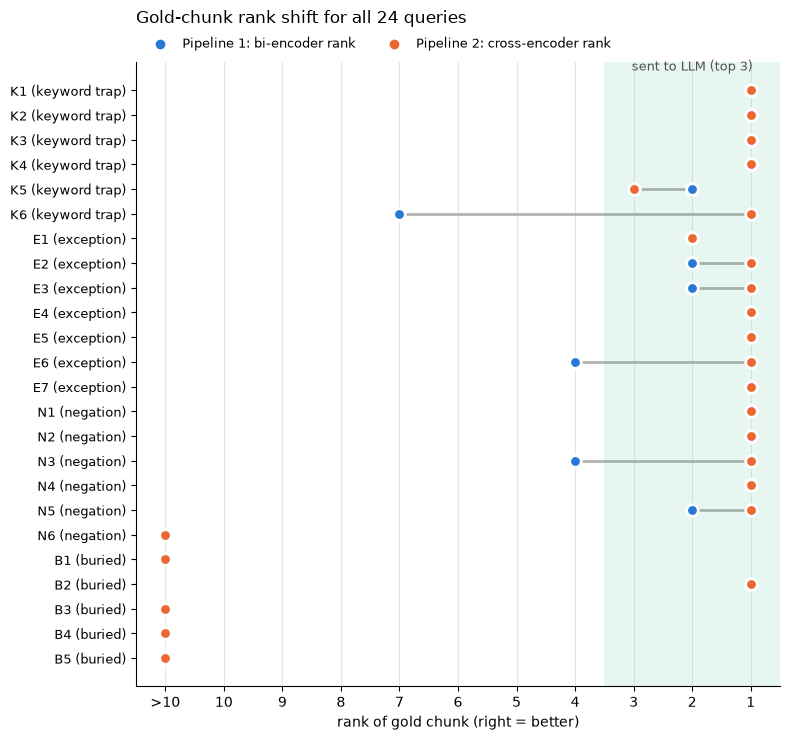

In [13]:
# Rank of the gold chunk before (blue) and after (orange) re-ranking, one row per query
fig, ax = plt.subplots(figsize=(8, 7.5))
order = rank_df.iloc[::-1].reset_index(drop=True)
for i, r in order.iterrows():
    a, b = r.base_rank, r.rerank_rank
    ax.plot([a, b], [i, i], color=C_GREY, lw=2, zorder=1)
    ax.scatter(a, i, s=70, color=C_BASE, edgecolor="white", linewidth=2, zorder=2)
    ax.scatter(b, i, s=70, color=C_RERANK, edgecolor="white", linewidth=2, zorder=3)
ax.axvspan(0.5, TOP_N + 0.5, color=C_GOLD, alpha=0.10, lw=0)
ax.text(2, len(order) - 0.2, "sent to LLM (top 3)", ha="center", color="#52514e", fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{r.qid} ({r.category})" for r in order.itertuples()], fontsize=9)
ax.set_xticks(range(1, 12)); ax.set_xticklabels([str(i) for i in range(1, 11)] + [">10"])
ax.set_xlim(0.5, 11.5); ax.invert_xaxis()
ax.set_xlabel("rank of gold chunk (right = better)")
ax.scatter([], [], color=C_BASE, label="Pipeline 1: bi-encoder rank"); ax.scatter([], [], color=C_RERANK, label="Pipeline 2: cross-encoder rank")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
plt.title("Gold-chunk rank shift for all 24 queries", loc="left", fontsize=12, pad=28)
plt.tight_layout(); plt.savefig(FIG_DIR / "rank_shift_all.png", dpi=150); plt.show()

## 9. Failure-mode deep dives

Now both LLM answers are generated for every query. The detailed analysis focuses on the queries where the gold chunk was **outside the baseline
top 3 but promoted into it by the cross-encoder** (outcome = FIXED), plus the cases where re-ranking **hurt** (reported for honesty).
For each one the notebook shows: the full top-10 table with both ranks and scores, a bump chart, and Answer 1 vs Answer 2 next to the clause a
correct answer needs.

In [14]:
# Generate Answer 1 and Answer 2 for every query (cached after the first run)
for qid, r in results.items():
    base_top = [c["chunk_id"] for c in sorted(r["candidates"], key=lambda c: c["bi_rank"])[:TOP_N]]
    rr_top   = [c["chunk_id"] for c in r["candidates"][:TOP_N]]
    r["base_top"], r["rr_top"] = base_top, rr_top
    r["prompt1"], r["prompt2"] = build_prompt(r["query"], base_top), build_prompt(r["query"], rr_top)
    r["answer1"], r["llm_s1"] = generate(r["query"], base_top)
    r["answer2"], r["llm_s2"] = generate(r["query"], rr_top)
    (OUT_DIR / "results").mkdir(exist_ok=True)
    (OUT_DIR / "results" / f"{qid}.json").write_text(json.dumps(r, indent=1, ensure_ascii=False), encoding="utf-8")

answers_df = pd.DataFrame([{"qid": q, "outcome": rank_df.set_index("qid").outcome[q],
                            "Answer 1 (baseline)": r["answer1"], "Answer 2 (re-ranked)": r["answer2"]}
                           for q, r in results.items()])
answers_df.to_csv(OUT_DIR / "answers_all_queries.csv", index=False)
print("answers generated for", len(answers_df), "queries")

answers generated for 24 queries


In [15]:
def short(cid, n=95):
    t = chunk_texts[cid].split("\n", 1)
    return f"{chunks[cid]['header'].split(' - ', 1)[-1][:40]} | {t[1][:n]}"

def show_candidates(qid):
    r = results[qid]
    df = pd.DataFrame([{"chunk": c["chunk_id"], "gold": "★" if c["chunk_id"] in r["gold"] else "",
                        "bi rank": c["bi_rank"], "cosine": round(c["bi_score"], 3),
                        "CE rank": c["ce_rank"], "CE score": round(c["ce_score"], 2),
                        "move": c["bi_rank"] - c["ce_rank"], "chunk text": short(c["chunk_id"])}
                       for c in sorted(r["candidates"], key=lambda c: c["bi_rank"])])
    return df.style.apply(lambda row: ["background-color: #d9f2e6" if row["gold"] else "" for _ in row], axis=1) \
             .hide(axis="index")

def bump_chart(qid, ax):
    r = results[qid]
    for c in r["candidates"]:
        g = c["chunk_id"] in r["gold"]
        ax.plot([0, 1], [c["bi_rank"], c["ce_rank"]], color=C_GOLD if g else C_GREY, lw=3 if g else 1.5, zorder=3 if g else 1)
        for x, rk in ((0, c["bi_rank"]), (1, c["ce_rank"])):
            ax.scatter(x, rk, s=40, color=C_GOLD if g else C_GREY, edgecolor="white", linewidth=1.5, zorder=4)
        ax.text(-0.06, c["bi_rank"], str(c["chunk_id"]), ha="right", va="center", fontsize=8, color="#52514e")
        ax.text(1.06, c["ce_rank"], str(c["chunk_id"]), ha="left", va="center", fontsize=8, color="#52514e")
    ax.axhspan(0.5, TOP_N + 0.5, color=C_GOLD, alpha=0.10, lw=0)
    ax.set_ylim(TOP_K + 0.5, 0.5); ax.set_xlim(-0.3, 1.3)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["bi-encoder", "cross-encoder"], fontsize=8)
    ax.set_yticks(range(1, TOP_K + 1)); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(qid, fontsize=10, loc="left"); ax.spines[["top", "right", "bottom"]].set_visible(False)

def show_answers(qid):
    r = results[qid]
    print(f"[{qid}] {r['query']}")
    print(f"Clause needed: {r['expected']}\n")
    print(f"Answer 1 (baseline top-3 = chunks {r['base_top']}):\n  {r['answer1']}\n")
    print(f"Answer 2 (re-ranked top-3 = chunks {r['rr_top']}):\n  {r['answer2']}")

fixed = rank_df[rank_df.outcome == "FIXED by re-ranking"].qid.tolist()
hurt  = rank_df[rank_df.outcome == "HURT by re-ranking"].qid.tolist()
print("fixed:", fixed, "| hurt:", hurt)

fixed: ['K6', 'E6', 'N3'] | hurt: []


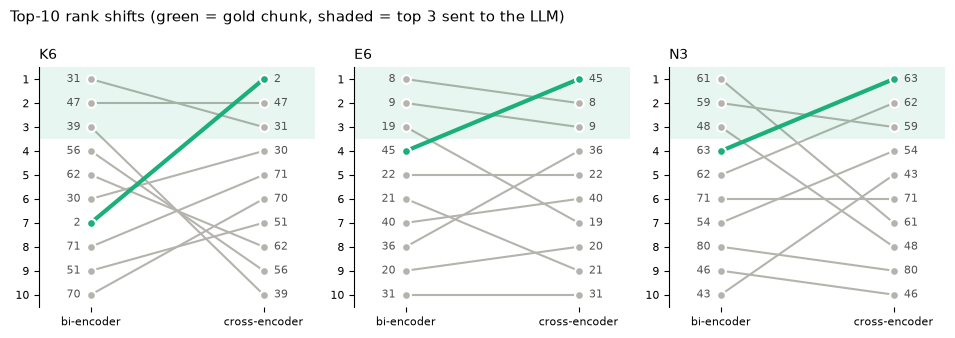

In [16]:
# Bump charts: every candidate's move from its bi-encoder rank (left) to its cross-encoder rank (right); gold chunk in green
show = fixed + hurt
ncol = min(len(show), 4); nrow = int(np.ceil(len(show) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.4 * nrow), squeeze=False)
for ax, qid in zip(axes.flat, show):
    bump_chart(qid, ax)
    if qid in hurt: ax.set_title(qid + " (hurt)", fontsize=10, loc="left")
for ax in list(axes.flat)[len(show):]:
    ax.axis("off")
plt.suptitle("Top-10 rank shifts (green = gold chunk, shaded = top 3 sent to the LLM)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "bump_charts.png", dpi=150); plt.show()

### 9.1 Answer quality for all 24 queries

I read every Answer 1 / Answer 2 against the expected clause and labelled it:
**correct** (states the deciding clause with the right conclusion), **partial** (right clause but an incomplete or self-contradictory conclusion),
**refusal** ("the context does not answer this"), **wrong** (a false statement presented as fact, i.e. a hallucination or misstated rule).

In [17]:
# Manual labels (one per answer) from reading answers_df against the "expected" clause of each query
ANSWER_LABELS = {   # qid: (Answer 1, Answer 2, note)
    "K1": ("wrong",   "correct", "A1 says Rs 200 crore (row 2 of the Schedule); the correct cap is Rs 250 crore"),
    "K2": ("correct", "correct", ""),
    "K3": ("correct", "correct", ""),
    "K4": ("correct", "partial", "A2 mixes in the 'purpose no longer served' rule"),
    "K5": ("correct", "correct", ""),
    "K6": ("refusal", "wrong",   "A2 claims the Act gives no age; s.2(f) (18 years) was in its context"),
    "E1": ("partial", "correct", "A1 concludes startups 'might need' to give notice"),
    "E2": ("correct", "partial", "A2 drops the 'specified purpose' ground for retention"),
    "E3": ("correct", "correct", ""),
    "E4": ("correct", "correct", ""),
    "E5": ("correct", "correct", ""),
    "E6": ("refusal", "partial", "A2 finds s.17(2)(b) but says the Act 'applies' - polarity inverted"),
    "E7": ("correct", "partial", "A2 garbles who the disclosure is to"),
    "N1": ("correct", "partial", "A2 omits the well-being and parental-consent limits"),
    "N2": ("partial", "partial", "both open with 'Yes, you can' before saying the waiver is invalid"),
    "N3": ("refusal", "correct", ""),
    "N4": ("correct", "correct", ""),
    "N5": ("partial", "partial", "both list only impersonation, not the other duties"),
    "N6": ("refusal", "refusal", "gold chunk outside the top 10"),
    "B1": ("partial", "partial", "both find the s.15 duty, neither finds the Rs 10,000 Schedule penalty"),
    "B2": ("correct", "correct", ""),
    "B3": ("refusal", "refusal", "gold chunk at bi-encoder rank 11"),
    "B4": ("refusal", "refusal", "gold chunk outside the top 10"),
    "B5": ("wrong",   "wrong",   "both claim you can go straight to the Board; s.13(3) says the opposite"),
}
lab = pd.DataFrame([{"qid": q, "Answer 1": a, "Answer 2": b, "note": n} for q, (a, b, n) in ANSWER_LABELS.items()])
lab = rank_df[["qid", "category", "shift", "outcome"]].merge(lab, on="qid")
lab.to_csv(OUT_DIR / "answer_labels.csv", index=False)
order = ["correct", "partial", "refusal", "wrong"]
counts = pd.DataFrame({"Answer 1 (baseline)": lab["Answer 1"].value_counts(),
                       "Answer 2 (re-ranked)": lab["Answer 2"].value_counts()}).reindex(order).fillna(0).astype(int)
display(counts); display(lab)

,Answer 1 (baseline),Answer 2 (re-ranked)
correct,12,11
partial,4,8
refusal,6,3
wrong,2,2


,qid,category,shift,outcome,Answer 1,Answer 2,note
0,K1,keyword trap,#1 -> #1,both OK,wrong,correct,A1 says Rs 200 crore (row 2 of the Schedule); the correct cap is Rs 250 crore
1,K2,keyword trap,#1 -> #1,both OK,correct,correct,
2,K3,keyword trap,#1 -> #1,both OK,correct,correct,
3,K4,keyword trap,#1 -> #1,both OK,correct,partial,A2 mixes in the 'purpose no longer served' rule
4,K5,keyword trap,#2 -> #3,both OK,correct,correct,
5,K6,keyword trap,#7 -> #1,FIXED by re-ranking,refusal,wrong,A2 claims the Act gives no age; s.2(f) (18 years) was in its context
6,E1,exception,#2 -> #2,both OK,partial,correct,A1 concludes startups 'might need' to give notice
7,E2,exception,#2 -> #1,both OK,correct,partial,A2 drops the 'specified purpose' ground for retention
8,E3,exception,#2 -> #1,both OK,correct,correct,
9,E4,exception,#1 -> #1,both OK,correct,correct,


### 9.2 Deep dive: N3 (negation): Rank #4 → #1, refusal → correct answer

*"What is the Board **prohibited** from doing when it inquires into a company?"* The deciding clause is s.28(8): *"The Board or its officers
**shall not** prevent access to any premises or take into custody any equipment…"*. The bi-encoder puts three chunks about the Board's
procedure and powers (what it **can** do) above it; their topic vectors are almost the same, and the single vector does not keep the "shall not".
The cross-encoder reads the query's "prohibited" against the chunk's "shall not" directly and moves chunk 63 to the top.

In [18]:
display(show_candidates("N3")); show_answers("N3")

chunk,gold,bi rank,cosine,CE rank,CE score,move,chunk text
61,,1,0.562000,7,-7.310000,-6,"Section 28: Procedure to be followed by | 28. (1) The Board shall function as an independent body and shall, as far as practicable, funct"
59,,2,0.554000,3,-3.250000,-1,Section 27: Powers and functions of Boar | (c) on a complaint made by a Data Principal in respect of a breach in observance by a Consent M
48,,3,0.547000,8,-7.530000,-5,"Section 18: Establishment of Board | 18. (1) With effect from such date as the Central Government may, by notification, appoint, the"
63,★,4,0.524000,1,-2.200000,3,Section 28: Procedure to be followed by | (8) The Board or its officers shall not prevent access to any premises or take into custody any
62,,5,0.518000,2,-3.020000,3,"Section 28: Procedure to be followed by | (5) In case the Board determines that there are sufficient grounds to proceed with inquiry, it"
71,,6,0.483000,6,-6.180000,0,Section 32: Voluntary undertaking | (5) Where a person fails to adhere to any term of the voluntary undertaking accepted by the Boa
54,,7,0.477000,4,-3.740000,3,Section 23: Proceedings of Board | 23. (1) The Board shall observe such procedure in regard to the holding of and transaction of b
80,,8,0.458000,9,-7.670000,-1,Section 39: Bar of jurisdiction | 39. No civil court shall have the jurisdiction to entertain any suit or proceeding in respect o
46,,9,0.449000,10,-9.560000,-1,"Section 17: Exemptions | (3) The Central Government may, having regard to the volume and nature of personal data process"
43,,10,0.440000,5,-4.530000,5,Section 17: Exemptions | (e) the processing is necessary for a scheme of compromise or arrangement or merger or amalgama


[N3] What is the Board prohibited from doing when it inquires into a company?
Clause needed: s.28(8): it shall not prevent access to premises or seize equipment in a way that affects day-to-day functioning.

Answer 1 (baseline top-3 = chunks [61, 59, 48]):
  The provided context does not answer this.

Answer 2 (re-ranked top-3 = chunks [63, 62, 59]):
  The Board is prohibited from preventing access to any premises or taking into custody any equipment or item that may adversely affect the day-to-day functioning of a person during the inquiry. This is stated in Section 28(8) of the Act.


### 9.3 Deep dive: E6 (exception): Rank #4 → #1, but the LLM inverts the exemption

*"Does the Act apply to personal data used for research or statistics?"* The answer is an **exemption** in s.17(2)(b). The bi-encoder ranks the
general "Application of Act" (s.3) and "Grounds for processing" (s.4) chunks first: they match the words "Act apply" and "personal data"
better than the exemption chunk does. After re-ranking the exemption is at #1 and Answer 2 quotes it, but the 3B model then says the Act
*"applies … if"* the conditions hold, when s.17(2) says the Act **shall not apply**. Retrieval was fixed, but the generator still made a polarity mistake.

In [19]:
display(show_candidates("E6")); show_answers("E6")

chunk,gold,bi rank,cosine,CE rank,CE score,move,chunk text
8,,1,0.612000,2,4.420000,-1,Section 3: Application of Act | (ii) personal data that is made or caused to be made publicly available by— (A) the Data Princi
9,,2,0.594000,3,0.970000,-1,Section 4: Grounds for processing person | 4. (1) A person may process the personal data of a Data Principal only in accordance with the p
19,,3,0.573000,7,-2.930000,-4,"Section 7: Certain legitimate uses | 7. A Data Fiduciary may process personal data of a Data Principal for any of following uses, na"
45,★,4,0.557000,1,6.920000,3,Section 17: Exemptions | (2) The provisions of this Act shall not apply in respect of the processing of personal data— (
22,,5,0.538000,5,-2.120000,0,"Section 7: Certain legitimate uses | (ii) such personal data is available in digital form in, or in non-digital form and digitised s"
21,,6,0.537000,9,-4.420000,-3,Section 7: Certain legitimate uses | (b) for the State and any of its instrumentalities to provide or issue to the Data Principal su
40,,7,0.523000,6,-2.890000,1,"Section 15: Duties of Data Principal | 15. A Data Principal shall perform the following duties, namely:— (a) comply with the provision"
36,,8,0.522000,4,0.500000,4,Section 11: Right to access information | (2) Nothing contained in clause (b) or clause (c) of sub-section (1) shall apply in respect of
20,,9,0.521000,8,-3.750000,1,Section 7: Certain legitimate uses | (a) for the specified purpose for which the Data Principal has voluntarily provided her persona
31,,10,0.505000,10,-5.520000,0,"Section 9: Processing of personal data o | (5) The Central Government may, if satisfied that a Data Fiduciary has ensured that its process"


[E6] Does the Act apply to personal data used for research or statistics?
Clause needed: s.17(2)(b): no, if the data is not used for decisions specific to a person and prescribed standards are followed.

Answer 1 (baseline top-3 = chunks [8, 9, 19]):
  The provided context does not explicitly mention research or statistics as specific uses for which the Act allows processing of personal data. However, it lists certain legitimate uses for processing personal data, including "for any of following uses, namely:" which could imply that if a use falls under these legitimate uses, the Act might apply. Research and statistics are not directly mentioned but could potentially fall under "certain legitimate uses" if they align with the conditions outlined in the Act.

Answer 2 (re-ranked top-3 = chunks [45, 8, 9]):
  Yes, the Act applies to personal data used for research or statistics if it is processed in accordance with prescribed standards and the data is not used to take decisions specific 

### 9.4 Deep dive: K6 (keyword trap): Rank #7 → #1, generation still fails

*"From what age is a person no longer treated as a child?"* The query's words ("age", "child") match s.9(5), the provision that lets the
government notify an **age above which** a Data Fiduciary is exempt from the child rules. That is a distractor. The answer is the definition in s.2(f)
("child" = not completed eighteen years), which sits in a long chunk with six other definitions. The cross-encoder lifts it from #7 to #1, but the
LLM still answers from the s.9(5) chunk. When the gold chunk is a dense list, getting it into the context is necessary but not sufficient.

In [20]:
display(show_candidates("K6")); show_answers("K6")

chunk,gold,bi rank,cosine,CE rank,CE score,move,chunk text
31,,1,0.383000,3,-9.030000,-2,"Section 9: Processing of personal data o | (5) The Central Government may, if satisfied that a Data Fiduciary has ensured that its process"
47,,2,0.372000,2,-8.770000,0,"Section 17: Exemptions | (5) The Central Government may, before expiry of five years from the date of commencement of th"
39,,3,0.367000,10,-10.670000,-7,"Section 14: Right to nominate | 14. (1) A Data Principal shall have the right to nominate, in such manner as may be prescribed,"
56,,4,0.353000,9,-10.390000,-5,"Section 25: Members and officers to be p | 25. The Chairperson, Members, officers and employees of the Board shall be deemed, when acting"
62,,5,0.334000,8,-10.160000,-3,"Section 28: Procedure to be followed by | (5) In case the Board determines that there are sufficient grounds to proceed with inquiry, it"
30,,6,0.331000,4,-9.090000,2,"Section 9: Processing of personal data o | 9. (1) The Data Fiduciary shall, before processing any personal data of a child or a person wit"
2,★,7,0.321000,1,-4.980000,6,"Section 2: Definitions | 2. In this Act, unless the context otherwise requires,— (a) “Appellate Tribunal” means the Tele"
71,,8,0.313000,5,-9.530000,3,Section 32: Voluntary undertaking | (5) Where a person fails to adhere to any term of the voluntary undertaking accepted by the Boa
51,,9,0.304000,7,-10.110000,2,Section 21: Disqualifications for appoin | 21. (1) A person shall be disqualified for being appointed and continued as the Chairperson or
70,,10,0.300000,6,-9.550000,4,Section 32: Voluntary undertaking | 32. (1) The Board may accept a voluntary undertaking in respect of any matter related to observ


[K6] From what age is a person no longer treated as a child under the Act?
Clause needed: s.2(f): a child is an individual who has not completed eighteen years.

Answer 1 (baseline top-3 = chunks [31, 47, 39]):
  The provided context does not explicitly state from what age a person is no longer treated as a child under the Act. It only mentions that the Central Government can notify an age above which a Data Fiduciary would be exempt from certain obligations regarding the processing of personal data of children.

Answer 2 (re-ranked top-3 = chunks [2, 47, 31]):
  According to Section 9 of Chapter II (Obligations Of Data Fiduciary), the Central Government may notify for processing by a Data Fiduciary the age above which that Data Fiduciary shall be exempt from the applicability of all or any of the obligations under sub-sections (1) and (3) in respect of processing by that Data Fiduciary as the notification may specify. This implies that there is no specific age mentioned as the cutoff 

### 9.5 Same gold rank, different answer: K1 (keyword trap)

The gold Schedule chunk is rank #1 in **both** pipelines, yet Answer 1 states the wrong amount. The baseline's other two chunks are s.33(2)
(how the Board sizes a penalty) and s.8(5) (the safeguard duty). Answer 1 says **Rs 200 crore**, which is row 2 of the Schedule (breach *notification*), not row 1.
Re-ranking replaced s.33(2) with a chunk about the Board's breach inquiry powers, and Answer 2 gives the correct **Rs 250 crore**.
The *other* chunks in the context also affect the answer.

In [21]:
display(show_candidates("K1")); show_answers("K1")

chunk,gold,bi rank,cosine,CE rank,CE score,move,chunk text
90,★,1,0.507000,1,1.240000,0,monetary penalties [See section 33(1)] | 1. Breach in observing the obligation of Data Fiduciary to take reasonable security safeguards
73,,2,0.504000,4,-6.420000,-2,"Section 33: Penalties | (2) While determining the amount of monetary penalty to be imposed under sub-section (1), the B"
26,,3,0.477000,2,-3.090000,1,"Section 8: General obligations of Data F | (5) A Data Fiduciary shall protect personal data in its possession or under its control, includ"
58,,4,0.460000,3,-6.250000,1,"Section 27: Powers and functions of Boar | 27. (1) The Board shall exercise and perform the following powers and functions, namely:— (a) o"
14,,5,0.460000,6,-9.100000,-1,Section 6: Consent | (2) Any part of consent referred in sub-section (1) which constitutes an infringement of the pr
5,,6,0.431000,7,-9.470000,-1,Section 2: Definitions | (i) an individual; (ii) a Hindu undivided family; (iii) a company; (iv) a firm; (v) an associat
59,,7,0.411000,5,-7.540000,2,Section 27: Powers and functions of Boar | (c) on a complaint made by a Data Principal in respect of a breach in observance by a Consent M
33,,8,0.404000,8,-9.820000,0,Section 10: Additional obligations of Si | (2) The Significant Data Fiduciary shall— (a) appoint a Data Protection Officer who shall— (i)
36,,9,0.404000,9,-9.870000,0,Section 11: Right to access information | (2) Nothing contained in clause (b) or clause (c) of sub-section (1) shall apply in respect of
11,,10,0.391000,10,-10.790000,0,Section 5: Notice | (2) Where a Data Principal has given her consent for the processing of her personal data before


[K1] What is the maximum fine if a company fails to protect user data from a security breach?
Clause needed: Schedule item 1: up to Rs 250 crore for failing to take reasonable security safeguards (s.8(5)).

Answer 1 (baseline top-3 = chunks [90, 73, 26]):
  According to section 33(1)(a) of the Act, if a Data Fiduciary breaches the obligation to take reasonable security safeguards to prevent personal data breaches as per section 8(5), the maximum monetary penalty is two hundred crore rupees.

Answer 2 (re-ranked top-3 = chunks [90, 26, 58]):
  According to section 33(1) of the Act, if a Data Fiduciary breaches the obligation to take reasonable security safeguards to prevent personal data breaches, the maximum fine is two hundred and fifty crore rupees.


### 9.6 Where re-ranking cannot help: the first-stage recall ceiling (B5, B1)

The cross-encoder only re-orders the 10 candidates it is given. For 5 of the 24 queries the gold chunk was never in the bi-encoder's top 10,
so both pipelines fail together. The worst outcome is **B5**: both answers *hallucinate* that a user can complain straight to the Board, when s.13(3) requires
exhausting the company's own grievance process first. **B1** needs two hops: "impersonation" is a duty in s.15, and its penalty is in a Schedule row that
says only *"duties under section 15"*, with no word in common with the query.

In [22]:
display(show_candidates("B5")); show_answers("B5")
print()
show_answers("B1")

chunk,gold,bi rank,cosine,CE rank,CE score,move,chunk text
64,,1,0.518000,1,-2.170000,0,"Section 28: Procedure to be followed by | (12) At any stage after receipt of a complaint, if the Board is of the opinion that the complai"
61,,2,0.478000,2,-6.790000,0,"Section 28: Procedure to be followed by | 28. (1) The Board shall function as an independent body and shall, as far as practicable, funct"
69,,3,0.407000,4,-8.170000,-1,"Section 31: Alternate dispute resolution | 31. If the Board is of the opinion that any complaint may be resolved by mediation, it may dire"
63,,4,0.364000,5,-9.440000,-1,Section 28: Procedure to be followed by | (8) The Board or its officers shall not prevent access to any premises or take into custody any
48,,5,0.359000,10,-10.910000,-5,"Section 18: Establishment of Board | 18. (1) With effect from such date as the Central Government may, by notification, appoint, the"
59,,6,0.347000,3,-7.870000,3,Section 27: Powers and functions of Boar | (c) on a complaint made by a Data Principal in respect of a breach in observance by a Consent M
54,,7,0.346000,6,-9.520000,1,Section 23: Proceedings of Board | 23. (1) The Board shall observe such procedure in regard to the holding of and transaction of b
70,,8,0.321000,9,-10.300000,-1,Section 32: Voluntary undertaking | 32. (1) The Board may accept a voluntary undertaking in respect of any matter related to observ
57,,9,0.307000,7,-9.790000,2,"Section 26: Powers of Chairperson | 26. The Chairperson shall exercise the following powers, namely:— (a) general superintendence a"
71,,10,0.306000,8,-10.150000,2,Section 32: Voluntary undertaking | (5) Where a person fails to adhere to any term of the voluntary undertaking accepted by the Boa


[B5] Do I have to approach the company first before complaining to the Board?
Clause needed: s.13(3): yes, the grievance redressal of the Data Fiduciary must be exhausted first.

Answer 1 (baseline top-3 = chunks [64, 61, 69]):
  No, according to Section 28(1), the Board can receive complaints and take action even if they determine there are insufficient grounds to proceed with an inquiry. This means you do not have to approach the company first; you can directly complain to the Board.

Answer 2 (re-ranked top-3 = chunks [64, 61, 59]):
  No, according to Section 27(2), the Board can receive complaints directly from the Data Principal without the need to approach the company first.

[B1] What penalty can a user face for impersonating someone else while sharing personal data?
Clause needed: Schedule item 5 (breach of s.15 duties): up to Rs 10,000.

Answer 1 (baseline top-3 = chunks [36, 40, 26]):
  The provided context does not explicitly state a penalty for impersonating someone else wh

In [23]:
# How deep would the first stage have to go?  Bi-encoder rank of the gold chunk over the WHOLE corpus,
# and its cross-encoder rank if the top 20 / top 30 bi-encoder candidates were re-ranked instead of the top 10.
rows = []
for qid in rank_df[rank_df.outcome.str.startswith("out of reach")].qid:
    q, gold = results[qid]["query"], results[qid]["gold"]
    full = baseline_retrieve(q, k=len(chunks))
    bi_full = min(c["bi_rank"] for c in full if c["chunk_id"] in gold)
    row = {"qid": qid, "bi-encoder rank (of 92)": bi_full}
    for k in (20, 30):
        rr = rerank(q, full[:k])
        hit = [c["ce_rank"] for c in rr if c["chunk_id"] in gold]
        row[f"CE rank if top-{k} re-ranked"] = hit[0] if hit else "not in pool"
    rows.append(row)
pd.DataFrame(rows)

,qid,bi-encoder rank (of 92),CE rank if top-20 re-ranked,CE rank if top-30 re-ranked
0,N6,50,not in pool,not in pool
1,B1,53,not in pool,not in pool
2,B3,11,1,1
3,B4,29,not in pool,2
4,B5,31,not in pool,not in pool


## 10. Latency profiling

Each stage is timed separately with `time.perf_counter()` (with `torch.cuda.synchronize()` around GPU work), after a warm-up,
over all 24 queries × 5 repeats. The cross-encoder is timed on both the GPU and the CPU, because many deployments rerank on CPU.
GPU and CPU runs are timed in separate loops; when they were interleaved, the laptop GPU dropped its clocks between calls and the GPU numbers came out inflated.
LLM time comes from the 48 generations in Section 9 and is the same for both pipelines (same prompt length, greedy decoding).

In [24]:
def timed(fn, *a, **kw):
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter(); out = fn(*a, **kw)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return out, (time.perf_counter() - t0) * 1000

cross_encoder_cpu = CrossEncoder(CROSS_ENCODER, device="cpu", max_length=512)
def rerank_cpu(query, cands):
    pairs = [(query, chunk_texts[c["chunk_id"]]) for c in cands]
    return cross_encoder_cpu.predict(pairs, batch_size=len(pairs), show_progress_bar=False)

for q in qdf["query"][:3]:   # warm-up (CUDA kernels, tokenizer caches)
    c = baseline_retrieve(q); rerank(q, c); rerank_cpu(q, c)

REPEATS = 5
gpu_rows, cpu_rows = [], []
for _ in range(REPEATS):                      # loop 1: everything that runs on the GPU
    for q in qdf["query"]:
        qv, t_emb = timed(bi_encoder.encode, [q], normalize_embeddings=True, convert_to_numpy=True)
        (_, ids), t_search = timed(index.search, qv.astype("float32"), TOP_K)
        cands = [{"chunk_id": int(i)} for i in ids[0]]
        _, t_ce = timed(rerank, q, cands)
        gpu_rows.append(dict(embed_ms=t_emb, search_ms=t_search, ce_gpu_ms=t_ce))
for _ in range(REPEATS):                      # loop 2: cross-encoder on the CPU
    for q in qdf["query"]:
        cands = baseline_retrieve(q)
        _, t_cpu = timed(rerank_cpu, q, cands)
        cpu_rows.append(dict(ce_cpu_ms=t_cpu))
lat = pd.concat([pd.DataFrame(gpu_rows), pd.DataFrame(cpu_rows)], axis=1)
lat.to_csv(OUT_DIR / "latency_raw.csv", index=False)

llm_times = pd.Series([r["llm_s1"] for r in results.values()] + [r["llm_s2"] for r in results.values()]) * 1000

def stat(s): return pd.Series({"median ms": s.median(), "p95 ms": s.quantile(0.95), "mean ms": s.mean()})
base_ret = lat.embed_ms + lat.search_ms
lat_table = pd.DataFrame({
    "query embedding (bi-encoder, GPU)":       stat(lat.embed_ms),
    "FAISS top-10 search (CPU)":               stat(lat.search_ms),
    "= Pipeline 1 retrieval":                  stat(base_ret),
    "cross-encoder, 10 pairs (GPU)":           stat(lat.ce_gpu_ms),
    "= Pipeline 2 retrieval (GPU re-rank)":    stat(base_ret + lat.ce_gpu_ms),
    "cross-encoder, 10 pairs (CPU)":           stat(lat.ce_cpu_ms),
    "= Pipeline 2 retrieval (CPU re-rank)":    stat(base_ret + lat.ce_cpu_ms),
    "LLM answer generation (Qwen2.5-3B, GPU)": stat(llm_times),
}).T.round(2)
e2e = pd.DataFrame({"median ms": {
    "Pipeline 1 end-to-end (retrieval + LLM)": base_ret.median() + llm_times.median(),
    "Pipeline 2 end-to-end (retrieval + GPU re-rank + LLM)": (base_ret + lat.ce_gpu_ms).median() + llm_times.median()}}).round(1)
lat_table.to_csv(OUT_DIR / "latency_table.csv")
display(lat_table); display(e2e)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 23254.93it/s]

,median ms,p95 ms,mean ms
"query embedding (bi-encoder, GPU)",6.50,10.22,7.05
FAISS top-10 search (CPU),0.06,0.11,0.07
= Pipeline 1 retrieval,6.57,10.39,7.12
"cross-encoder, 10 pairs (GPU)",20.05,30.57,21.51
= Pipeline 2 retrieval (GPU re-rank),27.38,38.78,28.62
"cross-encoder, 10 pairs (CPU)",200.63,230.41,202.84
= Pipeline 2 retrieval (CPU re-rank),208.08,237.13,209.95
"LLM answer generation (Qwen2.5-3B, GPU)",3047.10,6416.67,3359.32


,median ms
Pipeline 1 end-to-end (retrieval + LLM),3053.7
Pipeline 2 end-to-end (retrieval + GPU re-rank + LLM),3074.5


re-ranking overhead (GPU): +20.8 ms per query = 4.2x the baseline retrieval time
re-ranking overhead (CPU): +201.5 ms per query
share of end-to-end time spent re-ranking (GPU): 0.7%


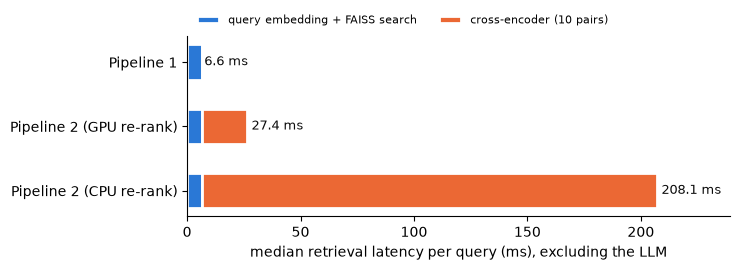

In [25]:
p1, p2g, p2c = base_ret.median(), (base_ret + lat.ce_gpu_ms).median(), (base_ret + lat.ce_cpu_ms).median()
print(f"re-ranking overhead (GPU): +{p2g - p1:.1f} ms per query = {p2g / p1:.1f}x the baseline retrieval time")
print(f"re-ranking overhead (CPU): +{p2c - p1:.1f} ms per query")
print(f"share of end-to-end time spent re-ranking (GPU): {(p2g - p1) / (p2g + llm_times.median()) * 100:.1f}%")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
labels = ["Pipeline 1", "Pipeline 2 (GPU re-rank)", "Pipeline 2 (CPU re-rank)"]
emb, srch = lat.embed_ms.median(), lat.search_ms.median()
ce = [0, lat.ce_gpu_ms.median(), lat.ce_cpu_ms.median()]
y = np.arange(3)[::-1]
ax.barh(y, [emb] * 3, color=C_BASE, height=0.55, label="query embedding + FAISS search", edgecolor="white", linewidth=2)
ax.barh(y, ce, left=[emb + srch] * 3, color=C_RERANK, height=0.55, label="cross-encoder (10 pairs)", edgecolor="white", linewidth=2)
for yi, tot in zip(y, [p1, p2g, p2c]):
    ax.text(tot + 1, yi, f"{tot:.1f} ms", va="center", fontsize=9, color="#0b0b0b")
ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel("median retrieval latency per query (ms), excluding the LLM")
ax.set_xlim(0, max(p1, p2g, p2c) * 1.15)
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / "latency_bars.png", dpi=150); plt.show()

## 11. Scaling: why not run the cross-encoder over the whole corpus?

Two measurements:
1. **Cost.** Cross-encoder time grows linearly with the number of chunks it must score, because every (query, chunk) pair needs a full transformer
   forward pass at query time and nothing can be pre-computed. I time it for 10 → all 92 chunks and extrapolate. The bi-encoder side is one
   query embedding plus an index lookup; chunk vectors are computed once offline.
2. **Quality.** For this small corpus it *is* possible to cross-encode all 92 chunks, so I check whether doing that ("CE-only") beats the two-stage pipeline.

In [26]:
sizes = [10, 25, 50, len(chunks)]
q_sample = qdf["query"].tolist()
scale_rows = []
for dev, model in (("GPU", cross_encoder), ("CPU", cross_encoder_cpu)):   # one device at a time (see Section 10)
    model.predict([(q_sample[0], t) for t in chunk_texts], batch_size=32, show_progress_bar=False)  # warm-up
    for n in sizes:
        ts = []
        for q in q_sample:
            pairs = [(q, chunk_texts[i]) for i in range(n)]
            _, t = timed(model.predict, pairs, batch_size=32, show_progress_bar=False)
            ts.append(t)
        scale_rows.append(dict(chunks_scored=n, device=dev, median_ms=np.median(ts)))
scale_df = pd.DataFrame(scale_rows)
per_chunk = {d: (scale_df[(scale_df.device == d) & (scale_df.chunks_scored == len(chunks))].median_ms.item() / len(chunks))
             for d in ("GPU", "CPU")}
display(scale_df.pivot(index="chunks_scored", columns="device", values="median_ms").round(1))

def human(sec):
    for unit, size in (("days", 86400), ("h", 3600), ("min", 60)):
        if sec >= size: return f"{sec / size:,.1f} {unit}"
    return f"{sec:.2f} s"

proj = pd.DataFrame([{"corpus size (chunks)": f"{N:,}",
                      "cross-encode everything, GPU": human(N * per_chunk['GPU'] / 1000),
                      "cross-encode everything, CPU": human(N * per_chunk['CPU'] / 1000),
                      "two-stage (bi-encoder + CE on 10), GPU": f"~{p2g:.0f} ms + ANN search"}
                     for N in (92, 10_000, 1_000_000, 100_000_000)])
proj.to_csv(OUT_DIR / "scaling_projection.csv", index=False)
print(f"per-chunk cross-encoder cost: GPU {per_chunk['GPU']:.2f} ms, CPU {per_chunk['CPU']:.2f} ms")
proj

device,CPU,GPU
chunks_scored,,
10,212.6,23.9
25,559.1,54.5
50,904.1,98.2
92,1562.9,157.9


per-chunk cross-encoder cost: GPU 1.72 ms, CPU 16.99 ms


,corpus size (chunks),"cross-encode everything, GPU","cross-encode everything, CPU","two-stage (bi-encoder + CE on 10), GPU"
0,92,0.16 s,1.56 s,~27 ms + ANN search
1,"10,000",17.17 s,2.8 min,~27 ms + ANN search
2,"1,000,000",28.6 min,4.7 h,~27 ms + ANN search
3,"100,000,000",2.0 days,19.7 days,~27 ms + ANN search


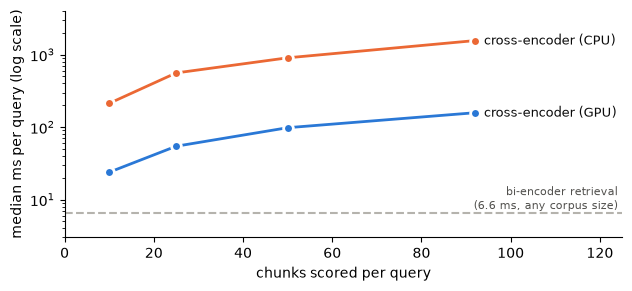

In [27]:
fig, ax = plt.subplots(figsize=(6.5, 3))
for dev, col in (("GPU", C_BASE), ("CPU", C_RERANK)):
    d = scale_df[scale_df.device == dev]
    ax.plot(d.chunks_scored, d.median_ms, marker="o", ms=7, lw=2, color=col, mec="white", mew=2)
    ax.text(d.chunks_scored.iloc[-1] + 2, d.median_ms.iloc[-1], f"cross-encoder ({dev})", va="center", fontsize=9, color="#0b0b0b")
ax.axhline(p1, color=C_GREY, ls="--", lw=1.5)
ax.text(124, p1, f"bi-encoder retrieval\n({p1:.1f} ms, any corpus size)", fontsize=8, color="#52514e", ha="right", va="bottom")
ax.set_yscale("log"); ax.set_ylim(3, 4000)
ax.set_xlabel("chunks scored per query"); ax.set_ylabel("median ms per query (log scale)"); ax.set_xlim(0, 125)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(FIG_DIR / "ce_scaling.png", dpi=150); plt.show()

In [28]:
# Quality check: does cross-encoding ALL chunks beat the two-stage pipeline on this small corpus?
full_ranks = []
for qid, cat, q, gold, exp in QUERIES:
    s = cross_encoder.predict([(q, t) for t in chunk_texts], batch_size=32, show_progress_bar=False)
    order = np.argsort(-s)
    full_ranks.append(min(int(np.where(order == g)[0][0]) + 1 for g in gold))
rank_df["ce_only_rank"] = [r if r <= TOP_K else TOP_K + 1 for r in full_ranks]
cmp_df = pd.DataFrame({"Pipeline 1 (bi-encoder)": metrics(rank_df.base_rank),
                       "Pipeline 2 (bi-encoder -> CE top 10)": metrics(rank_df.rerank_rank),
                       "CE over all chunks (no first stage)": metrics(rank_df.ce_only_rank)}).T.round(3)
cmp_df

,Hit@1,Hit@3,MRR@10,Recall@10
Pipeline 1 (bi-encoder),0.458,0.667,0.589,0.792
Pipeline 2 (bi-encoder -> CE top 10),0.708,0.792,0.743,0.792
CE over all chunks (no first stage),0.750,0.917,0.833,0.958


## 12. Saved artifacts

In [29]:
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(ROOT)):55s} {p.stat().st_size/1024:8.1f} KB")

artifacts\answer_labels.csv                                  2.1 KB
artifacts\answers_all_queries.csv                           14.0 KB
artifacts\chunk_embeddings.npy                             138.1 KB
artifacts\chunks.jsonl                                      81.0 KB
artifacts\figures\bump_charts.png                          121.2 KB
artifacts\figures\ce_scaling.png                            39.4 KB
artifacts\figures\chunk_token_hist.png                      20.8 KB
artifacts\figures\latency_bars.png                          29.8 KB
artifacts\figures\rank_shift_all.png                       111.5 KB
artifacts\latency_raw.csv                                    9.0 KB
artifacts\latency_table.csv                                  0.4 KB
artifacts\llm_cache.json                                    19.9 KB
artifacts\rank_shift_all_queries.csv                         1.2 KB
artifacts\results\B1.json                                    7.7 KB
artifacts\results\B2.json                       